# Ride-Hailing in Pakistan
- **Student Name:** Iyad Rahim
- **ERP ID:** 36103
- **Course:** ICA – Introduction to Python Programming and Data Analysis for Business (IBA)
- **Instructor:** Dr. Know All

## Load and Inspect Dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

rides_df = pd.read_csv("ride_hailing_dataset.csv")
print("Dataset dimensions:", rides_df.shape)
print("\nMissing values per column:")
print(rides_df.isna().sum())

Dataset dimensions: (100, 8)

Missing values per column:
trip_id           0
city              0
service_type      0
fare              0
distance_km       0
payment_method    0
trip_rating       0
gender            0
dtype: int64


### Q1: What is the average fare by service type?

In [2]:
avg_fare_service = rides_df.groupby("service_type")["fare"].mean().sort_values(ascending=False).round(2)
print("Average fare by service type:")
print(avg_fare_service)

Average fare by service type:
service_type
InDrive     573.51
Careem      544.98
Rickshaw    486.64
Uber        486.13
Name: fare, dtype: float64


### Q2: Which city has the most trips?

In [3]:
city_trip_counts = rides_df["city"].value_counts()
print(city_trip_counts)
print(f"\nCity with most trips: {city_trip_counts.index[0]} ({city_trip_counts.iloc[0]} trips)")

city
Islamabad     29
Lahore        26
Karachi       23
Rawalpindi    22
Name: count, dtype: int64

City with most trips: Islamabad (29 trips)


### Q3: What is the average distance per trip?

In [4]:
mean_distance = round(rides_df["distance_km"].mean(), 2)
print(f"Average distance per trip: {mean_distance} km")

Average distance per trip: 9.61 km


### Q4: Compare trip ratings by gender.

In [5]:
gender_ratings = rides_df.groupby("gender")["trip_rating"].mean().round(2)
print("Average trip rating by gender:")
print(gender_ratings)

Average trip rating by gender:
gender
Female    2.82
Male      3.33
Name: trip_rating, dtype: float64


### Q5: Make a bar chart of service type vs. average fare.

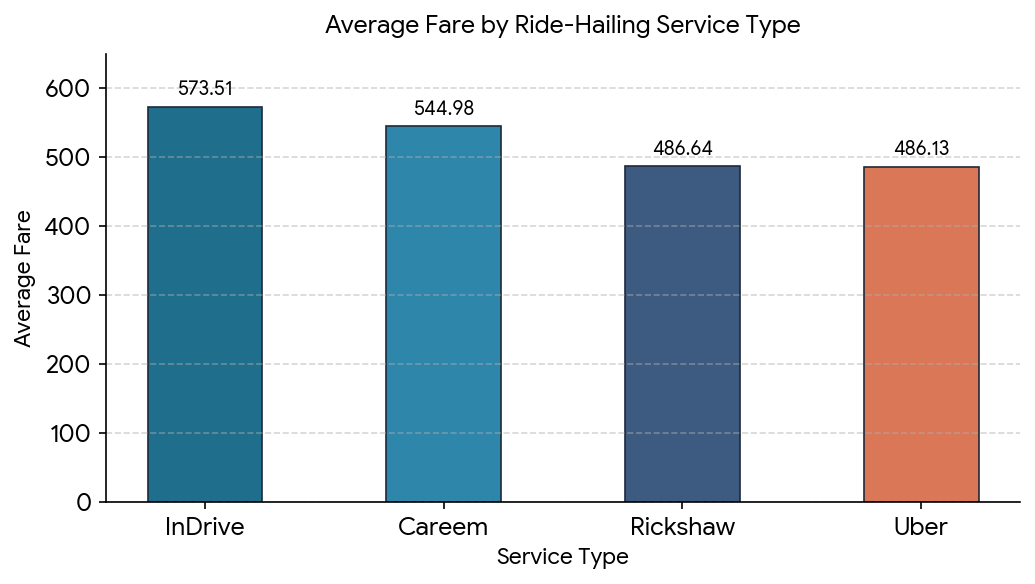

In [6]:
fare_by_service = rides_df.groupby("service_type")["fare"].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(
    fare_by_service.index,
    fare_by_service.values,
    width=0.48,
    color=["#1F6E8C", "#2E86AB", "#3D5A80", "#D97757"],
    edgecolor="#1E293B",
    linewidth=0.8
)
ax.set_title("Average Fare by Ride-Hailing Service Type", fontsize=12, fontweight="bold", pad=10)
ax.set_xlabel("Service Type")
ax.set_ylabel("Average Fare")
ax.set_ylim(0, 650)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 10,
        f"{height:.2f}",
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()